In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/NLP_Project_1.2'
os.chdir(PROJECT_PATH)
print("Directory:", os.getcwd())
print("Files:", os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directory: /content/drive/.shortcut-targets-by-id/1UO8obemgHZHMyFhGNo_MbgyFqnUGyEId/NLP_Project_1.2
Files: ['Sentences_AllAgree.txt', 'Sentences_75Agree.txt', 'Sentences_66Agree.txt', 'Sentences_50Agree.txt', 'finetuned-bert', 'ExperimentSummarySheet_Ex1.xlsx', 'NLP_Project_1.2.ipynb']


# Task 1: Exploratory Data Analysis

# of unique words:  10071


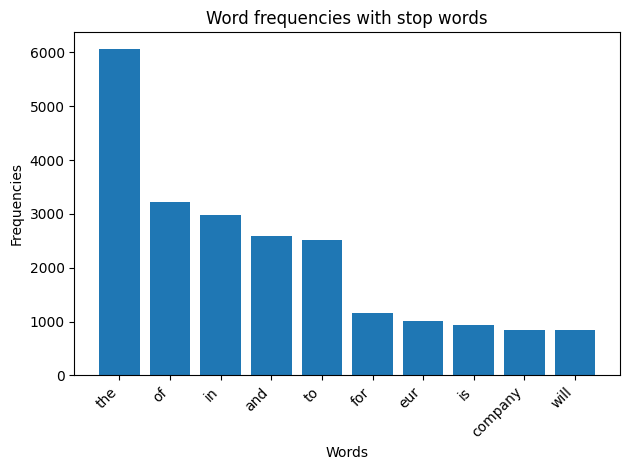

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import scipy.sparse
from typing import cast
import numpy as np
import matplotlib.pyplot as plt

# Read file to content variable
lines = ""
with open("Sentences_50Agree.txt", "r", encoding='latin-1') as file:
    lines = file.readlines()

sentences = []
labels = []
for line in lines:
    line = line.strip()  # kills the \n and spaces
    if '@' in line:
        parts = line.split('@')
        label = parts[-1].strip()  # get the clean sentiment label
        sentence = "@".join(parts[:-1]).strip()  # rebuild sentence

        sentences.append(sentence)
        labels.append(label)
"""
# create array of tuples with sentences and labels
sentences_labels = list(map(lambda x: x.split("@"), lines))
sentences = list(map(lambda x: x[0], sentences_labels))
labels = list(map(lambda x: x[1], sentences_labels))
"""
# bag of words vectors
bow_vectorizer = CountVectorizer()
X_bow = cast(scipy.sparse.csr_matrix, bow_vectorizer.fit_transform(sentences))
word_counts = np.sum(X_bow.toarray(), axis=0)
sort_by_freq = np.flip(word_counts.argsort())

unique_words = bow_vectorizer.get_feature_names_out()
print("# of unique words: ", len(unique_words))

# plot word frequencies WITH stop words
plt.bar(unique_words[sort_by_freq][:10],word_counts[sort_by_freq][:10])
plt.title('Word frequencies with stop words')
plt.xlabel('Words')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Frequencies')
plt.tight_layout()
plt.show()
plt.clf()

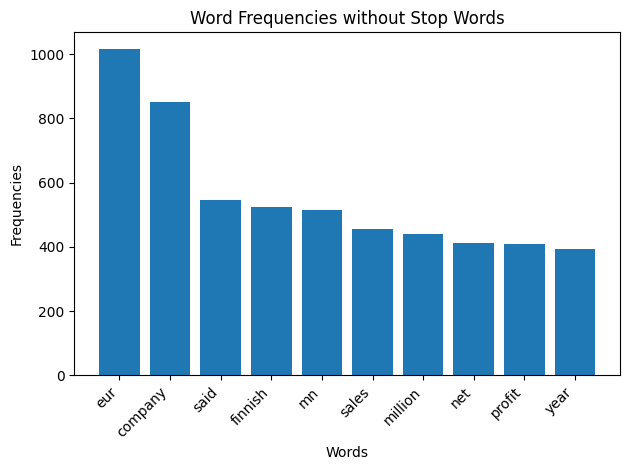

Top 10 words without stop words:
eur : 1017
company : 851
said : 545
finnish : 524
mn : 515
sales : 455
million : 440
net : 413
profit : 410
year : 395


<Figure size 640x480 with 0 Axes>

In [ ]:
# Word frequencies without stop words

# drop common english stop words
vec_no_stop = CountVectorizer(stop_words='english')
X_ns = vec_no_stop.fit_transform(sentences)

# sum up frequencies and sort them desc
word_counts_ns = np.sum(X_ns.toarray(), axis=0)
sorted_ns = np.flip(word_counts_ns.argsort())
words_ns = vec_no_stop.get_feature_names_out()

top_words = words_ns[sorted_ns][:10]
top_counts = word_counts_ns[sorted_ns][:10]

plt.bar(top_words, top_counts)
plt.title('Word Frequencies without Stop Words')
plt.xlabel('Words')
plt.xticks(rotation=45, ha='right') # rotate labels so they don't overlap
plt.ylabel('Frequencies')
plt.tight_layout()
plt.show()
plt.clf()

print("Top 10 words without stop words:")
for i in range(10):
    print(top_words[i], ":", top_counts[i])

label
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64


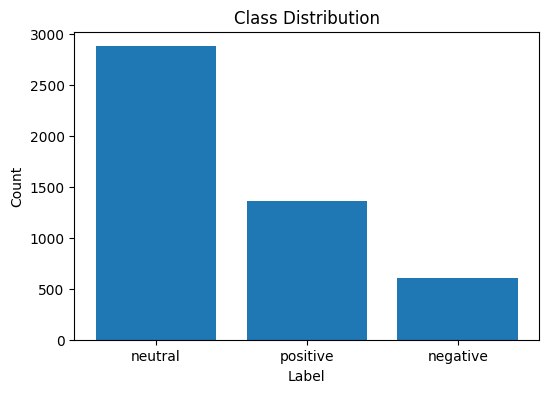

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import seaborn as sns

#class distribution

df = pd.DataFrame({'sentence': sentences, 'label': labels})

label_counts = df['label'].value_counts()
print(label_counts)

plt.figure(figsize=(6, 4))
plt.bar(label_counts.index, label_counts.values)
plt.title('Class Distribution')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()
plt.clf()


count    4846.000000
mean       23.101114
std         9.958474
min         2.000000
25%        16.000000
50%        21.000000
75%        29.000000
max        81.000000
Name: word_count, dtype: float64


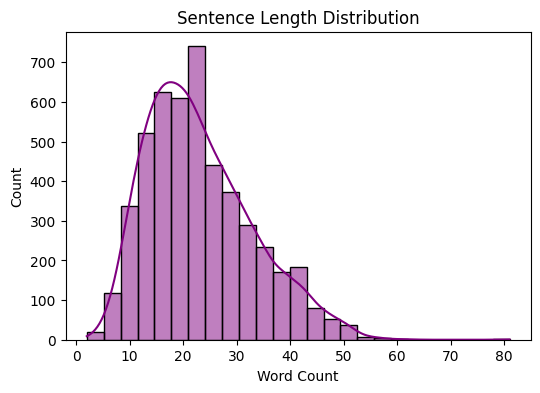

<Figure size 640x480 with 0 Axes>

In [ ]:
#text length analysis
df['word_count'] = df['sentence'].apply(lambda x: len(x.split()))
print(df['word_count'].describe())

plt.figure(figsize=(6, 4))
sns.histplot(df['word_count'], bins=25, kde=True, color='purple')
plt.title('Sentence Length Distribution')
plt.xlabel('Word Count')
plt.ylabel('Count')
plt.show()
plt.clf()

# Task 2: Text Preprocessing

In [ ]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


def clean_doc(doc):
   doc = doc.lower()
   doc = re.sub(r'\d+', '', doc) # removes digits
   doc = doc.translate(str.maketrans('', '', string.punctuation)) # remove punctuation
   doc = re.sub(r'\W+', ' ', doc) # matches any non word character; word characters are a-Z, 0-9 and _
   doc = re.sub(r'\s+', ' ', doc).strip() # matches whitespace characters
   return doc

def preprocess_corpus(lines, tokenized=False):
    cleaned_lines = [clean_doc(doc) for doc in lines] # remove noise
    tokenized_lines = [word_tokenize(doc) for doc in cleaned_lines] # tokenize corpus
    stop_words = set(stopwords.words('english'))
    filtered_lines = [[word for word in doc if word not in stop_words] for doc in tokenized_lines] # remove stop words
    stemmer = PorterStemmer()
    stemmed_corpus = [[stemmer.stem(word) for word in doc] for doc in filtered_lines] # get the word root/stem
    prepared_corpus = [" ".join(x) for x in stemmed_corpus] # detokenize the lines (sklearn does its own tokenizing)

    return prepared_corpus


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
print("Before preprocessing:", sentences[0])
sentences = preprocess_corpus(sentences)
print("After preprocessing:", sentences[0])
print("Total sentences:", len(sentences))

Before preprocessing: According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .
After preprocessing: accord gran compani plan move product russia although compani grow
Total sentences: 4846


# Task 3: Sentiment Classification

### Test/Train Split

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix


# Encode labels to integers
le = LabelEncoder()
labels = le.fit_transform(labels)

#convert lists to numpy arrays to use indexing
sentences_np = np.array(sentences)
labels_np = np.array(labels)

#stratified split to keep the class distribution same in train and test sets
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in sss.split(sentences_np, labels_np):
    sentences_train = sentences_np[train_index]
    sentences_test = sentences_np[test_index]
    labels_train = labels_np[train_index]
    labels_test = labels_np[test_index]

"""
# Split the data into training and test
split_boundary = round(len(sentences) * 0.8)
# Train set
sentences_train = sentences[:split_boundary]
labels_train = labels[:split_boundary]
# Test set
sentences_test = sentences[split_boundary:]
labels_test = labels[split_boundary:]
"""
#Prepare different vector representations
# Bag of Words
bow_vectorizer = CountVectorizer()
X_bow_train = bow_vectorizer.fit_transform(sentences_train).toarray()
X_bow_test = bow_vectorizer.transform(sentences_test).toarray()

# Bag of N-gram
bigram_vectorizer = CountVectorizer(ngram_range=(1,2))
X_ngram_train = bigram_vectorizer.fit_transform(sentences_train).toarray()
X_ngram_test = bigram_vectorizer.transform(sentences_test).toarray()

# Tf-idf
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2))
X_tfidf_train = tfidf_vectorizer.fit_transform(sentences_train).toarray()
X_tfidf_test = tfidf_vectorizer.transform(sentences_test).toarray()

### Naive Bayes

Naive Bayes + bow
              precision    recall  f1-score   support

    negative       0.65      0.56      0.60       121
     neutral       0.77      0.84      0.80       576
    positive       0.60      0.52      0.56       273

    accuracy                           0.71       970
   macro avg       0.67      0.64      0.65       970
weighted avg       0.71      0.71      0.71       970



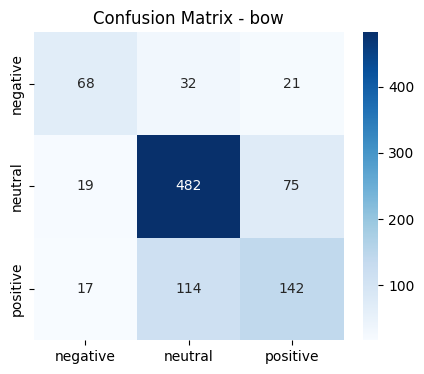

Naive Bayes + N-gram
              precision    recall  f1-score   support

    negative       0.75      0.40      0.53       121
     neutral       0.75      0.90      0.82       576
    positive       0.62      0.49      0.55       273

    accuracy                           0.72       970
   macro avg       0.71      0.60      0.63       970
weighted avg       0.72      0.72      0.71       970



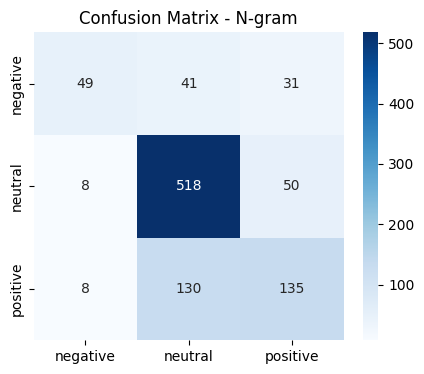

Naive Bayes + TF-IDF
              precision    recall  f1-score   support

    negative       1.00      0.07      0.14       121
     neutral       0.68      0.99      0.80       576
    positive       0.66      0.29      0.40       273

    accuracy                           0.68       970
   macro avg       0.78      0.45      0.45       970
weighted avg       0.71      0.68      0.61       970



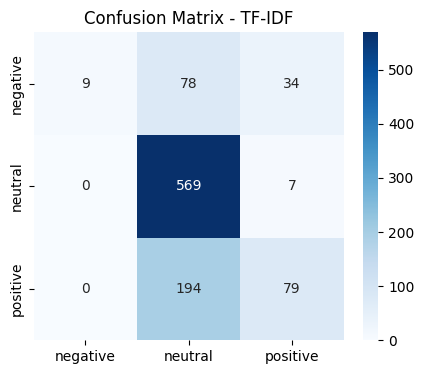

In [ ]:
mnb = MultinomialNB()

# BoW
mnb.fit(X_bow_train, labels_train)
preds_bow = mnb.predict(X_bow_test)
print("Naive Bayes + bow")
print(classification_report(labels_test, preds_bow, target_names=le.classes_))

cm = confusion_matrix(labels_test, preds_bow)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - bow')
plt.show()

# N-gram
mnb.fit(X_ngram_train, labels_train)
preds_ngram = mnb.predict(X_ngram_test)
print("Naive Bayes + N-gram")
print(classification_report(labels_test, preds_ngram, target_names=le.classes_))

cm = confusion_matrix(labels_test, preds_ngram)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - N-gram')
plt.show()

# TF-IDF
mnb.fit(X_tfidf_train, labels_train)
preds_tfidf = mnb.predict(X_tfidf_test)
print("Naive Bayes + TF-IDF")
print(classification_report(labels_test, preds_tfidf, target_names=le.classes_))

cm = confusion_matrix(labels_test, preds_tfidf)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - TF-IDF')
plt.show()

### Feed Forward NN

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0268 - sparse_categorical_accuracy: 0.7330
Test accuracy using 128 units: 0.7329896688461304
              precision    recall  f1-score   support

    negative       0.59      0.58      0.58       121
     neutral       0.79      0.82      0.81       576
    positive       0.66      0.61      0.63       273

    accuracy                           0.73       970
   macro avg       0.68      0.67      0.67       970
weighted avg       0.73      0.73      0.73       970



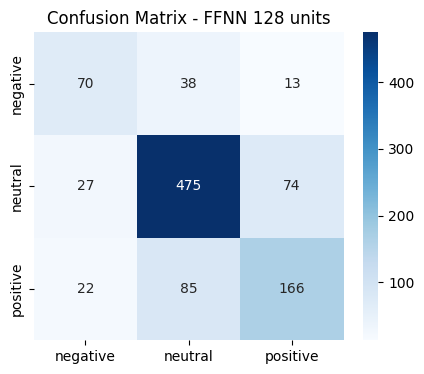

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.8021 - sparse_categorical_accuracy: 0.7515
Test accuracy using 128 units: 0.7515463829040527
              precision    recall  f1-score   support

    negative       0.67      0.49      0.56       121
     neutral       0.77      0.90      0.83       576
    positive       0.72      0.56      0.63       273

    accuracy                           0.75       970
   macro avg       0.72      0.65      0.67       970
weighted avg       0.75      0.75      0.74       970



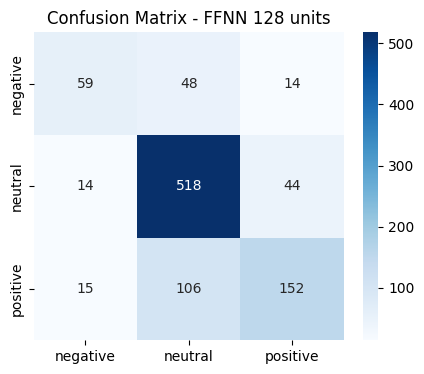

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.7631 - sparse_categorical_accuracy: 0.7412
Test accuracy using 128 units: 0.7412371039390564
              precision    recall  f1-score   support

    negative       0.64      0.55      0.60       121
     neutral       0.79      0.85      0.82       576
    positive       0.66      0.59      0.62       273

    accuracy                           0.74       970
   macro avg       0.70      0.66      0.68       970
weighted avg       0.73      0.74      0.74       970



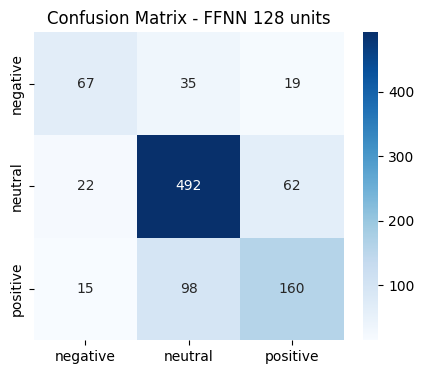

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy
import random

# Global seeds
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

num_labels = 3

def run_ffnn(X_train, X_test, y_train, y_test, num_labels=3,label_encoder=None):
  if label_encoder is None:
    label_encoder = le

  # Reset seeds before each run for reproducibility
  random.seed(42)
  np.random.seed(42)
  tf.random.set_seed(42)

  best_model = None
  for w in [128]:
    # Build the model
    ffnn = Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),
        Dense(units=w, activation='relu'),
        Dense(units=num_labels, activation='softmax')
    ])

    # Compile the model
    ffnn.compile(
        optimizer=Adam(),
        loss=SparseCategoricalCrossentropy(),
        metrics=[SparseCategoricalAccuracy]
    )

    # Train the model
    ffnn.fit(X_train, y_train, epochs=10, batch_size=32, verbose=0)

    # Evaluate the model
    test_loss, test_acc = ffnn.evaluate(X_test, y_test)
    print(f"Test accuracy using {w} units: {test_acc}")

    # detailed metrics
    preds = ffnn.predict(X_test, verbose=0).argmax(axis=1)
    pred_labels = label_encoder.inverse_transform(preds)
    true_labels = label_encoder.inverse_transform(y_test)
    print(classification_report(true_labels, pred_labels))

    if num_labels == 2:
      class_labels = ['negative', 'positive']
    else:
      class_labels = ['negative', 'neutral', 'positive']
    cm = confusion_matrix(true_labels, pred_labels, labels=class_labels)

    #cm = confusion_matrix(true_labels, pred_labels, labels=['negative', 'neutral', 'positive'])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.title('Confusion Matrix - FFNN ' + str(w) + ' units')
    plt.show()

    if w == 128:  # best performing model, save for error analysis
      best_model =ffnn

  return best_model

# Run ffnn with bow, n-gram and tfidf
for idx, data in enumerate([(X_bow_train, X_bow_test),(X_ngram_train, X_ngram_test),(X_tfidf_train, X_tfidf_test)]):
  if idx == 1: model = run_ffnn(data[0], data[1], labels_train, labels_test)
  else: run_ffnn(data[0], data[1], labels_train, labels_test)


### Prepare data for binary classification

In [ ]:
# binary classification - remove neutral class (neutral = 1)
sentences_bin_list = []
labels_bin_list = []

for s, l in zip(sentences, labels):
    if l != 1:  # 1 = neutral
        sentences_bin_list.append(s)
        labels_bin_list.append(l)

sentences_bin = np.array(sentences_bin_list)
labels_bin = np.array(labels_bin_list)

# re-map binary labels: 0 (negative) stays 0, 2 (positive) becomes 1
labels_bin = np.where(labels_bin == 2, 1, labels_bin)
le_bin = LabelEncoder()
le_bin.classes_ = np.array(['negative', 'positive'])

# stratified split for binary
sss_bin = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in sss_bin.split(sentences_bin, labels_bin):
    sentences_train_bin = sentences_bin[train_index]
    sentences_test_bin = sentences_bin[test_index]
    labels_train_bin = labels_bin[train_index]
    labels_test_bin = labels_bin[test_index]

print("Binary class distribution:")
unique, counts = np.unique(labels_bin, return_counts=True)
for label, count in zip(unique, counts):
    print(le_bin.classes_[label], ":", count)

Binary class distribution:
negative : 604
positive : 1363


### Binary classification with Naive Bayes

Naive Bayes Binary + bow
              precision    recall  f1-score   support

    negative       0.70      0.76      0.73       121
    positive       0.89      0.86      0.87       273

    accuracy                           0.83       394
   macro avg       0.80      0.81      0.80       394
weighted avg       0.83      0.83      0.83       394



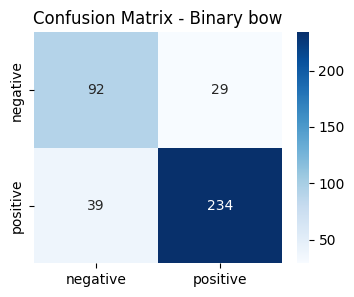

Naive Bayes Binary + N-gram
              precision    recall  f1-score   support

    negative       0.77      0.65      0.71       121
    positive       0.86      0.91      0.88       273

    accuracy                           0.83       394
   macro avg       0.81      0.78      0.79       394
weighted avg       0.83      0.83      0.83       394



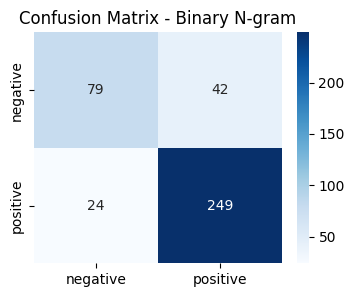

Naive Bayes Binary + TF-IDF
              precision    recall  f1-score   support

    negative       0.97      0.25      0.39       121
    positive       0.75      1.00      0.86       273

    accuracy                           0.77       394
   macro avg       0.86      0.62      0.63       394
weighted avg       0.82      0.77      0.71       394



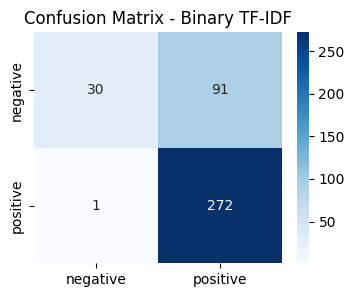

In [ ]:
# Naive Bayes on binary dataset (negative positive only)
# vectorization for binary
bow_vectorizer_bin = CountVectorizer()
X_bow_train_bin = bow_vectorizer_bin.fit_transform(sentences_train_bin).toarray()
X_bow_test_bin = bow_vectorizer_bin.transform(sentences_test_bin).toarray()

bigram_vectorizer_bin = CountVectorizer(ngram_range=(1,2))
X_ngram_train_bin = bigram_vectorizer_bin.fit_transform(sentences_train_bin).toarray()
X_ngram_test_bin = bigram_vectorizer_bin.transform(sentences_test_bin).toarray()

tfidf_vectorizer_bin = TfidfVectorizer()
X_tfidf_train_bin = tfidf_vectorizer_bin.fit_transform(sentences_train_bin).toarray()
X_tfidf_test_bin = tfidf_vectorizer_bin.transform(sentences_test_bin).toarray()

bin_classes = ['negative', 'positive']
mnb_bin = MultinomialNB()

# bow
mnb_bin.fit(X_bow_train_bin, labels_train_bin)
preds_bow_bin = mnb_bin.predict(X_bow_test_bin)
print("Naive Bayes Binary + bow")
print(classification_report(labels_test_bin, preds_bow_bin, target_names=bin_classes))

cm = confusion_matrix(labels_test_bin, preds_bow_bin)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=bin_classes, yticklabels=bin_classes)
plt.title('Confusion Matrix - Binary bow')
plt.show()

# N-gram
mnb_bin.fit(X_ngram_train_bin, labels_train_bin)
preds_ngram_bin = mnb_bin.predict(X_ngram_test_bin)
print("Naive Bayes Binary + N-gram")
print(classification_report(labels_test_bin, preds_ngram_bin, target_names=bin_classes))

cm = confusion_matrix(labels_test_bin, preds_ngram_bin)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=bin_classes, yticklabels=bin_classes)
plt.title('Confusion Matrix - Binary N-gram')
plt.show()

# TF-IDF
mnb_bin.fit(X_tfidf_train_bin, labels_train_bin)
preds_tfidf_bin = mnb_bin.predict(X_tfidf_test_bin)
print("Naive Bayes Binary + TF-IDF")
print(classification_report(labels_test_bin, preds_tfidf_bin, target_names=bin_classes))

cm = confusion_matrix(labels_test_bin, preds_tfidf_bin)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=bin_classes, yticklabels=bin_classes)
plt.title('Confusion Matrix - Binary TF-IDF')
plt.show()

### Binary classification with FFNN

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.4299 - sparse_categorical_accuracy: 0.8401
Test accuracy using 128 units: 0.8401015400886536
              precision    recall  f1-score   support

    negative       0.75      0.71      0.73       121
    positive       0.88      0.90      0.89       273

    accuracy                           0.84       394
   macro avg       0.81      0.80      0.81       394
weighted avg       0.84      0.84      0.84       394



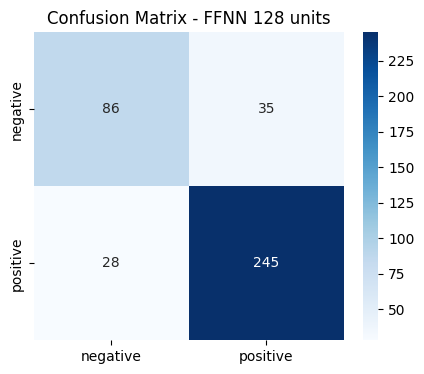

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.3715 - sparse_categorical_accuracy: 0.8579
Test accuracy using 128 units: 0.8578680157661438
              precision    recall  f1-score   support

    negative       0.81      0.70      0.75       121
    positive       0.88      0.93      0.90       273

    accuracy                           0.86       394
   macro avg       0.84      0.81      0.83       394
weighted avg       0.86      0.86      0.85       394



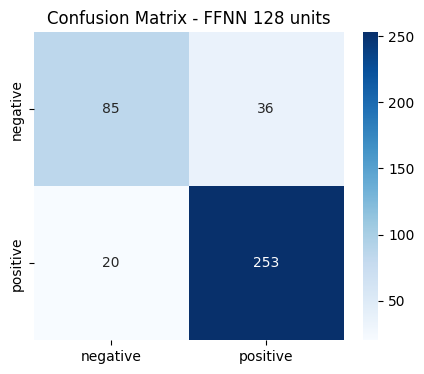

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.4053 - sparse_categorical_accuracy: 0.8147
Test accuracy using 128 units: 0.8147208094596863
              precision    recall  f1-score   support

    negative       0.71      0.68      0.69       121
    positive       0.86      0.88      0.87       273

    accuracy                           0.81       394
   macro avg       0.78      0.78      0.78       394
weighted avg       0.81      0.81      0.81       394



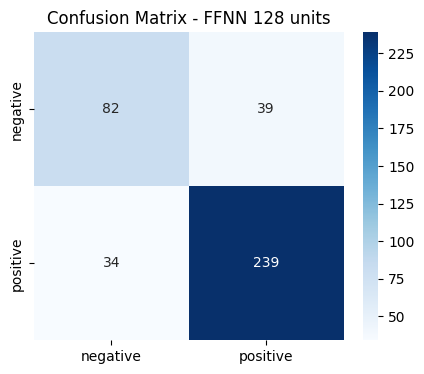

In [ ]:
# FFNN on binary dataset
# Run ffnn with bow, n-gram and tfidf for binary
for data in [(X_bow_train_bin, X_bow_test_bin),(X_ngram_train_bin, X_ngram_test_bin),(X_tfidf_train_bin, X_tfidf_test_bin)]:
  run_ffnn(data[0], data[1], labels_train_bin, labels_test_bin, num_labels=2, label_encoder=le_bin)

### Error analysis naive bayes using N-gram

In [ ]:
# Task 3: Error Analysis for Naive Bayes (N-gram)

# our best NB configuration
mnb.fit(X_ngram_train, labels_train)
preds_ngram = mnb.predict(X_ngram_test)

print("Sample Misclassified Examples (NB N-gram) ")

error_counter = 0

# first 10 mistakes
for sentence, true_index, pred_index in zip(sentences_test, labels_test, preds_ngram):
    if true_index != pred_index:
        error_counter += 1

        # decode numbers back to text labels like positive
        true_label = le.classes_[true_index]
        pred_label = le.classes_[pred_index]

        print(f"\nExample {error_counter}:")
        print(f"Sentence:  {sentence}")
        print(f"True:      {true_label}")
        print(f"Predicted: {pred_label}")

        # stop after printing first 10
        if error_counter == 10:
            break



Sample Misclassified Examples (NB N-gram) 

Example 1:
Sentence:  subscript increas cargotec share capit euro
True:      positive
Predicted: neutral

Example 2:
Sentence:  diesel margin remain high
True:      positive
Predicted: neutral

Example 3:
Sentence:  nordea move new headquart signifi begin new era
True:      positive
Predicted: neutral

Example 4:
Sentence:  ore bodi suffici support anticip product least year
True:      neutral
Predicted: positive

Example 5:
Sentence:  nest oil extend yesterday gain put pct eur util fortum shed pct eur
True:      neutral
Predicted: positive

Example 6:
Sentence:  addit russia seek addit growth ukrain
True:      positive
Predicted: neutral

Example 7:
Sentence:  nonrecur item eur mn profit amount eur mn
True:      neutral
Predicted: negative

Example 8:
Sentence:  staff recruit japan complement network close servic locat countri worldwid
True:      positive
Predicted: neutral

Example 9:
Sentence:  combin deep domain expertis applic servic man

### Error analysis for FFNN 128 units with Ngram

In [ ]:
# error analysis - FFNN 128 units
ffnn_preds = model.predict(X_ngram_test, verbose=0).argmax(axis=1)

error_counter = 0

for sentence, true_index, pred_index in zip(sentences_test, labels_test, ffnn_preds):
    if true_index != pred_index:
        error_counter += 1

        true_label = le.classes_[true_index]
        pred_label = le.classes_[pred_index]

        print(f"\nExample {error_counter}:")
        print(f"Sentence:  {sentence}")
        print(f"True:      {true_label}")
        print(f"Predicted: {pred_label}")

        if error_counter == 10:
            break


Example 1:
Sentence:  diesel margin remain high
True:      positive
Predicted: negative

Example 2:
Sentence:  nordea move new headquart signifi begin new era
True:      positive
Predicted: neutral

Example 3:
Sentence:  ore bodi suffici support anticip product least year
True:      neutral
Predicted: positive

Example 4:
Sentence:  nonrecur item eur mn profit amount eur mn
True:      neutral
Predicted: negative

Example 5:
Sentence:  staff recruit japan complement network close servic locat countri worldwid
True:      positive
Predicted: neutral

Example 6:
Sentence:  combin deep domain expertis applic servic manag asm outsourc servic offer prove win combin
True:      positive
Predicted: neutral

Example 7:
Sentence:  compani also featur ethibel pioneer invest regist includ innovest global list world sustain corpor
True:      positive
Predicted: neutral

Example 8:
Sentence:  paper maker stora enso oyj said friday acquit charg particip paper pricefix conspiraci unit state
True:      

# Task 4: PMI-based similarity


In [ ]:
# calculate PMI for 10 random words
import random
from numpy.linalg import norm

# return a list of all unique words in corpus
def get_unique_words(corpus):
  whole_corpus = " ".join(corpus)
  tokenized_corpus = whole_corpus.split(" ")
  unique_words = sorted(list(set(tokenized_corpus)))
  return unique_words

# returns a np array which maps every words to cooccurence frequencies
def generate_cooc_matrix(corpus):
  # use a matrix to count co-occurence
  unique_words = get_unique_words(corpus)
  cooc_matrix = np.zeros((len(unique_words),len(unique_words)), dtype=int)

  # loop over sentences and words in corpus
  for s in corpus:
    s_tokenized = s.split(" ")
    for i, w in enumerate(s_tokenized):
      # increment counter for context word before word w
      if i>0:
        cooc_matrix[unique_words.index(w)][unique_words.index(s_tokenized[i-1])] += 1
      # increment counter for context word after word w
      if i<len(s_tokenized)-1:
        cooc_matrix[unique_words.index(w)][unique_words.index(s_tokenized[i+1])] += 1

  return cooc_matrix

# return a ppmi vector for every word in corpus
def calc_ppmi(corpus):
  unique_words = get_unique_words(corpus)
  cooc_matrix = generate_cooc_matrix(corpus)

  total = cooc_matrix.sum()
  p_w = cooc_matrix.sum(axis=1, keepdims=True) / total
  p_c = cooc_matrix.sum(axis=0, keepdims=True) / total
  p_wc = cooc_matrix / total

  with np.errstate(divide='ignore', invalid='ignore'):
    pmi = np.log2(p_wc / (p_w * p_c))

  return np.where(np.isfinite(pmi), np.maximum(pmi, 0), 0)

# calculate cosine similarity for each vector
def cos_similarity(vec_a, vec_b):
  return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

def find_most_similar_for_samples(corpus):
  ppmi_matrix = calc_ppmi(corpus)
  unique_words = get_unique_words(corpus)

  # word frequency count
  word_counts = {}
  for sent in corpus:
    for word in sent.split():
      word_counts[word] = word_counts.get(word, 0) + 1

  # find 10 sample words
  random.seed(42)
  frequent_words = sorted([w for w in unique_words if w and word_counts.get(w, 0) > 5])
  random_words = random.sample(frequent_words, k=10)
  for word in random_words:
    w_idx = unique_words.index(word)
    vec_a = ppmi_matrix[w_idx]
    similarities = []

    for idx, vec_b in enumerate(ppmi_matrix):
      if idx == w_idx: continue
      if not unique_words[idx]:  # skip empty string
        continue

      sim = cos_similarity(vec_a, vec_b)

      similarities.append((unique_words[idx], sim))

    similarities.sort(key=lambda x: x[1], reverse=True)
    top5 = [w for w, s in similarities[:5]]
    print(f"Most similar pmi for [{word}]: {top5}")

find_most_similar_for_samples(sentences)


/tmp/ipykernel_5319/1146444008.py:48: RuntimeWarning: invalid value encountered in scalar divide
  return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))


Most similar pmi for [storag]: ['impli', 'dye', 'ecommerc', 'rock', 'marietta']
Most similar pmi for [commit]: ['flsmidth', 'violat', 'honor', 'testament', 'timetomarket']
Most similar pmi for [also]: ['courtship', 'iraq', 'patrick', 'histor', 'would']
Most similar pmi for [wireless]: ['mobilebas', 'mobil', 'satellit', 'g', 'centric']
Most similar pmi for [gp]: ['modem', 'vdw', 'xm', 'hunt', 'tracker']
Most similar pmi for [follow]: ['matador', 'ci', 'tweepl', 'barum', 'yearli']
Most similar pmi for [far]: ['minera', 'fennia', 'kivimeist', 'meiklejohn', 'walden']
Most similar pmi for [cours]: ['boot', 'yellowandblu', 'hapoel', 'relianc', 'prematur']
Most similar pmi for [wherebi]: ['riihimñki', 'lextel', 'expir', 'vsevolozhsk', 'borlñng']
Most similar pmi for [claim]: ['hervi', 'payout', 'hasten', 'tallinnhelisnki', 'error']


# Task 5

### Normal execution of Bert model

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, pipeline
from datasets import Dataset

# Convert training data to dataset
dataset_train = Dataset.from_dict({
    "text": sentences_train,
    "label": labels_train
})

dataset_test = Dataset.from_dict({
    "text": sentences_test,
    "label": labels_test
})

# Tokenize the data for Bert
model_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(data):
  return bert_tokenizer(data["text"], truncation=True, max_length=128)

dataset_train = dataset_train.map(tokenize, batched=True)
dataset_test = dataset_test.map(tokenize, batched=True)

# Data collator to handle padding
data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

# Get model
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

# Fine tune / train model
args = TrainingArguments(
    output_dir="./finetuned-bert",
    learning_rate=2.0e-5,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=dataset_train,
    eval_dataset=dataset_test,
    data_collator=data_collator,
)

trainer.train()

# Test prediction
predictions = trainer.predict(dataset_test)
preds = np.argmax(predictions.predictions, axis=-1)
print(classification_report(
    predictions.label_ids, preds,
    target_names=le.classes_
))



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Map:   0%|          | 0/3876 [00:00<?, ? examples/s]

Map:   0%|          | 0/970 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,No log,0.645064
2,No log,0.588769
3,0.665673,0.607273


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

              precision    recall  f1-score   support

    negative       0.61      0.79      0.68       121
     neutral       0.81      0.84      0.82       576
    positive       0.71      0.56      0.63       273

    accuracy                           0.75       970
   macro avg       0.71      0.73      0.71       970
weighted avg       0.76      0.75      0.75       970



In [ ]:
# Convert training data to dataset
dataset_train = Dataset.from_dict({
    "text": sentences_train_bin,
    "label": labels_train_bin
})
dataset_test = Dataset.from_dict({
    "text": sentences_test_bin,
    "label": labels_test_bin
})

dataset_train = dataset_train.map(tokenize, batched=True)
dataset_test = dataset_test.map(tokenize, batched=True)

# Data collator to handle padding
data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

# Get model
model_bin = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

trainer_bin = Trainer(
    model=model_bin,
    args=args,
    train_dataset=dataset_train,
    eval_dataset=dataset_test,
    data_collator=data_collator,
)

trainer_bin.train()

# Test prediction
predictions = trainer_bin.predict(dataset_test)
preds = np.argmax(predictions.predictions, axis=-1)
print(classification_report(
    predictions.label_ids, preds,
    target_names=le_bin.classes_
))



Column([1, 0, 1, 1, 1])


Map:   0%|          | 0/1573 [00:00<?, ? examples/s]

Map:   0%|          | 0/394 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,No log,0.382516
2,No log,0.295222
3,No log,0.300613


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

              precision    recall  f1-score   support

    negative       0.71      0.88      0.79       121
    positive       0.94      0.84      0.89       273

    accuracy                           0.85       394
   macro avg       0.83      0.86      0.84       394
weighted avg       0.87      0.85      0.86       394

